# 01 · Data preparation and quality

**Goal:** turn the raw NYC Open Data billing extract into a clean development × month table and a documented
data-quality assessment, without silently dropping anything.

**Rules applied**
1. The raw file is never modified; every record keeps `record_id` (its line position in the file).
2. Only exact duplicates and superseded bill re-issues are *excluded*. Each exclusion is logged with a reason.
3. Everything else unusual (credits, demand-only lines, extreme cost per kWh, estimated reads) is *flagged and kept*.

All logic lives in `src/nycha_energy/prepare.py`; this notebook runs it and shows the evidence behind each decision.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.0f}")
from nycha_energy import config, prepare, analysis, forecast, viz

## 1. Inspect the source before aggregating

In [2]:
raw = prepare.load_raw()
print(f"{len(raw):,} rows × {raw.shape[1]} columns")
raw.head(3).T

445,111 rows × 28 columns


,0,1,2
record_id,1,2,3
development_name,MOTT HAVEN,SAMUEL (CITY),MARBLE HILL
borough,BRONX,MANHATTAN,BRONX
account_name,MOTT HAVEN,SAMUEL (CITY),MARBLE HILL
location,BLD 04,BLD 22,BLD 02
meter_amr,NONE,NONE,INTERVAL
meter_scope,NaN,NaN,NaN
tds,121,377,49
edp,244,650,638
rc_code,B012100,M037700,B004900


In [3]:
df = prepare.standardise(raw)
print("Revenue months:", df.revenue_month.min().date(), "→", df.revenue_month.max().date())
print("Unparseable revenue months:", df.revenue_month.isna().sum())
end_year = prepare.detect_end_year(df)
print("Last complete calendar year (all 12 revenue months present):", end_year)

Revenue months: 2010-01-01 → 2023-01-01
Unparseable revenue months: 0
Last complete calendar year (all 12 revenue months present): 2022


### What does one row represent?

`UMIS BILL ID` is **not** unique, and a single bill ID can cover many meters. A development (`TDS #`) has many meters.
So each row is **one meter line on one bill for one revenue month**. Repeated development-month rows are expected and
are not duplicates.

In [4]:
w = df[df.revenue_month.dt.year.between(config.START_YEAR, end_year)]
print("Rows in window:", f"{len(w):,}")
print("Distinct bill IDs:", f"{w.umis_bill_id.nunique():,}")
print("Meters per bill ID (distribution):")
print(w.groupby("umis_bill_id").meter_number.nunique().describe().round(1).to_string())
print("\nDevelopment names per TDS #:", w.groupby("tds").development_name.nunique().max(),
      "| boroughs per TDS #:", w.groupby("tds").borough.nunique().max())

Rows in window: 181,331
Distinct bill IDs: 49,290
Meters per bill ID (distribution):
count   49,290
mean    3.3000
std     8.8000
min     1.0000
25%     1.0000
50%     1.0000
75%     1.0000
max         94

Development names per TDS #: 1 | boroughs per TDS #: 1


In [5]:
# Bill components reconcile exactly to the total charge on every row
gap = (w.current_charges - (w.kwh_charges + w.kw_charges + w.other_charges)).abs()
print("Rows where components ≠ total (>$0.01):", int((gap > 0.01).sum()))

Rows where components ≠ total (>$0.01): 0


## 2. Duplicates vs legitimate repeats

Monthly row counts double in a few months. That pattern points to exact duplicates first.

In [6]:
counts = w.groupby(w.revenue_month.dt.strftime("%Y-%m")).size()
exact = w.duplicated(subset=list(prepare.COLUMN_MAP.values()))
after = w[~exact].groupby(w[~exact].revenue_month.dt.strftime("%Y-%m")).size()
pd.DataFrame({"rows": counts, "exact_duplicates": w[exact].groupby(w[exact].revenue_month.dt.strftime("%Y-%m")).size(),
              "after_exact_dedup": after}).fillna(0).astype(int).query("exact_duplicates > 0")

,rows,exact_duplicates,after_exact_dedup
revenue_month,,,
2019-09,3395,2,3393
2020-01,6708,2764,3944
2020-02,6718,2686,4032
2020-03,6714,2279,4435
2020-04,6719,2131,4588
2021-01,6759,2298,4461
2021-02,6751,1699,5052
2022-01,6771,1914,4857


After removing exact copies, some **meter + revenue month + service period** combinations still appear under
*different bill IDs with different amounts*. That pattern fits a corrected, re-issued bill better than an additional meter:

In [7]:
k = ["tds", "meter_number", "revenue_month", "service_start", "service_end"]
d = w[~exact]
multi = d[d.duplicated(k, keep=False)].sort_values(k + ["umis_bill_id"])
print(f"{multi.groupby(k, dropna=False).ngroups:,} meter-periods with more than one version")
multi[["development_name", "meter_number", "revenue_month", "service_start", "service_end",
       "umis_bill_id", "kwh", "current_charges", "estimated"]].head(8)

6,407 meter-periods with more than one version


,development_name,meter_number,revenue_month,service_start,service_end,umis_bill_id,kwh,current_charges,estimated
86870,FIRST HOUSES,5669805,2021-01-01,2020-12-23,2021-01-26,9746027,"1,212",151,N
86626,FIRST HOUSES,5669805,2021-01-01,2020-12-23,2021-01-26,9947911,"1,224",135,Y
82938,FIRST HOUSES,5669805,2021-02-01,2021-01-26,2021-02-25,9853256,"1,128",165,Y
77830,FIRST HOUSES,5669805,2021-02-01,2021-01-26,2021-02-25,9947972,"1,068",125,N
86871,FIRST HOUSES,6469176,2021-01-01,2020-12-23,2021-01-26,9746027,"7,398",935,Y
86631,FIRST HOUSES,6469176,2021-01-01,2020-12-23,2021-01-26,9947911,"7,380",865,Y
82939,FIRST HOUSES,6469176,2021-02-01,2021-01-26,2021-02-25,9853256,"8,514","1,265",Y
77829,FIRST HOUSES,6469176,2021-02-01,2021-01-26,2021-02-25,9947972,"8,604","1,022",N


**Decision:** keep the version with the highest bill ID (bill IDs rise over time in this file), and log the rest as
`superseded_bill`. Summing the versions would double-count. The sensitivity of this choice is quantified below and in
the data-quality report.

## 3. Run the preparation pipeline

In [8]:
prep = prepare.prepare()
pd.Series(prep.counts).to_frame("value")

,value
raw_rows,445111
raw_min_month,2010-01-01 00:00:00
raw_max_month,2023-01-01 00:00:00
unparseable_revenue_month,0
outside_window_rows,263780
window_rows,181331
exact_duplicates,15773
superseded_bills,5888
near_duplicates_same_bill,519
retained_rows,159151


In [9]:
c = prep.counts
kept_cost = prep.records.current_charges.sum()
print(f"Cost retained:                 ${kept_cost:,.0f}")
print(f"Cost if re-issues were summed: ${c['cost_if_reissues_summed']:,.0f}  ({c['cost_if_reissues_summed']/kept_cost-1:+.1%})")
prep.exclusions.groupby("reason").agg(records=("record_id", "size"), kwh=("kwh", "sum"), cost=("current_charges", "sum"))

Cost retained:                 $640,925,616
Cost if re-issues were summed: $652,295,031  (+1.8%)


,records,kwh,cost
reason,,,
exact_duplicate,15773,"451,703,455","50,722,968"
near_duplicate_same_bill,519,"5,867,337","746,884"
superseded_bill,5888,"111,617,779","10,622,531"


## 4. Quality flags (retained records)

In [10]:
r = prep.records
flags = pd.DataFrame({"records": r[prepare.FLAG_COLS].sum(),
                      "share": r[prepare.FLAG_COLS].mean(),
                      "cost_involved": [r.loc[r[f], "current_charges"].sum() for f in prepare.FLAG_COLS]})
print(f"Row-level cost/kWh bounds (0.5–99.5 pct): ${prep.rate_bounds[0]:.3f} – ${prep.rate_bounds[1]:.3f}")
flags.sort_values("records", ascending=False)

Row-level cost/kWh bounds (0.5–99.5 pct): $0.021 – $0.385


,records,share,cost_involved
flag_zero_kwh_positive_cost,57871,0.3636,"92,961,207"
flag_demand_only,57726,0.3627,"92,809,255"
flag_estimated,53554,0.3365,"190,667,345"
flag_bill_exception,13934,0.0876,"41,506,546"
flag_zero_kwh_zero_cost,1069,0.0067,0.0000
flag_extreme_rate_high,500,0.0031,"4,262,328"
flag_extreme_rate_low,500,0.0031,"292,641"
flag_split_meter,488,0.0031,"7,218,591"
flag_unusual_service_days,232,0.0015,"1,296,131"
flag_negative_cost,215,0.0014,"-37,584"


**Zero kWh with positive cost is mostly not an error.** Nearly all of these rows carry kW demand, meaning they are
demand-charge lines billed separately from energy. They stay in the totals, which is why *effective cost per kWh* is
an all-in measure and not a tariff rate.

**Negative costs** are treated as credits or adjustments and surfaced in the `credits` column.

In [11]:
print("Zero-kWh positive-cost rows that carry kW demand:",
      f"{r.flag_demand_only.sum() / r.flag_zero_kwh_positive_cost.sum():.1%}")
r.nlargest(5, "row_rate")[["record_id", "development_name", "revenue_month", "meter_number", "kwh",
                            "current_charges", "row_rate"]]

Zero-kWh positive-cost rows that carry kW demand: 99.7%


,record_id,development_name,revenue_month,meter_number,kwh,current_charges,row_rate
16042,18453,WEST BRIGHTON II,2022-07-01,9863107_S017500-12.2%,"69,491","3,551,569",51
154212,178786,WEST BRIGHTON I,2019-02-01,7860113_1600-87.8%,548,"27,063",49
114427,132310,MORRISANIA,2020-02-01,8096662-58.5,222,"9,216",42
49358,54708,REDFERN,2021-09-01,80659819,262,"8,281",32
51520,56870,BEACH 41ST STREET-BEACH CHANNEL DRIVE,2021-09-01,80340656,141,"3,061",22


The top row alone, **record 18453** (West Brighton II, July 2022), bills \$3.55M for 69k kWh. The same meter bills
about \$4–6k in the months either side. It is the single largest charge in the file and is carried into the investigation table.

## 5. Development × month table and coverage

In [12]:
dm = prepare.development_month(prep.records, prep.start_year, prep.end_year)
print(dm.shape)
dm.head()

(16080, 33)


,tds,development_name,borough,revenue_month,year,month,kwh,cost,kw,kwh_charges,kw_charges,other_charges,credits,n_records,n_meters,...,n_zero_kwh_positive_cost,n_extreme_rate,n_bill_exception,n_reissued,top_record_id,top_record_cost,primary_vendor,funding_source,is_missing_month,mwh,effective_cost_per_kwh,typical_meters,meter_count_ratio,flag_meter_count_change,has_quality_flag
0,1,FIRST HOUSES,MANHATTAN,2019-01-01,2019,1,"21,492","2,723",37,824,289,"1,611",0.0000,8,8,...,0,0,0,0,183566,"1,060",NEW YORK POWER AUTHORITY,FEDERAL,False,21,0.1267,8.0000,1.0000,False,False
1,1,FIRST HOUSES,MANHATTAN,2019-02-01,2019,2,"19,338","2,701",37,741,286,"1,673",0.0000,8,8,...,0,0,0,0,178963,"1,088",NEW YORK POWER AUTHORITY,FEDERAL,False,19,0.1397,8.0000,1.0000,False,False
2,1,FIRST HOUSES,MANHATTAN,2019-03-01,2019,3,"16,656","2,941",34,639,269,"2,034",0.0000,8,8,...,0,0,8,0,176804,"1,234",NEW YORK POWER AUTHORITY,FEDERAL,False,17,0.1766,8.0000,1.0000,False,True
3,1,FIRST HOUSES,MANHATTAN,2019-04-01,2019,4,"15,540","1,920",31,596,245,"1,079",0.0000,8,8,...,0,0,8,0,173057,800,NEW YORK POWER AUTHORITY,FEDERAL,False,16,0.1235,8.0000,1.0000,False,True
4,1,FIRST HOUSES,MANHATTAN,2019-05-01,2019,5,"17,292","2,486",36,663,283,"1,540",0.0000,8,8,...,0,0,0,0,170606,948,NEW YORK POWER AUTHORITY,FEDERAL,False,17,0.1438,8.0000,1.0000,False,False


In [13]:
cont = prepare.continuity(dm, prep.end_year - 1)
print(f"Developments: {len(cont)} | continuous monthly history through {prep.end_year-1}: {cont.is_continuous.sum()}")
dm.groupby("year").agg(missing_dev_months=("is_missing_month", "sum"),
                       meter_count_changes=("flag_meter_count_change", "sum"))

Developments: 335 | continuous monthly history through 2021: 328


,missing_dev_months,meter_count_changes
year,,
2019,42,185
2020,12,108
2021,14,111
2022,88,219


In [14]:
pm = analysis.portfolio_monthly(dm)
pm[["revenue_month", "developments_reporting", "meters_reporting"]].tail(6)

,revenue_month,developments_reporting,meters_reporting
42,2022-07-01,328,3193
43,2022-08-01,329,3192
44,2022-09-01,328,3184
45,2022-10-01,327,3140
46,2022-11-01,325,3056
47,2022-12-01,316,2650


Reporting thins out at the end of the file: the last months have far fewer meters reporting. Totals for those months
are understated by **missing bills**, not necessarily by lower demand. The forecast evaluation excludes such months from
scoring, and the cost bridge isolates them in a *non-comparable* bar.

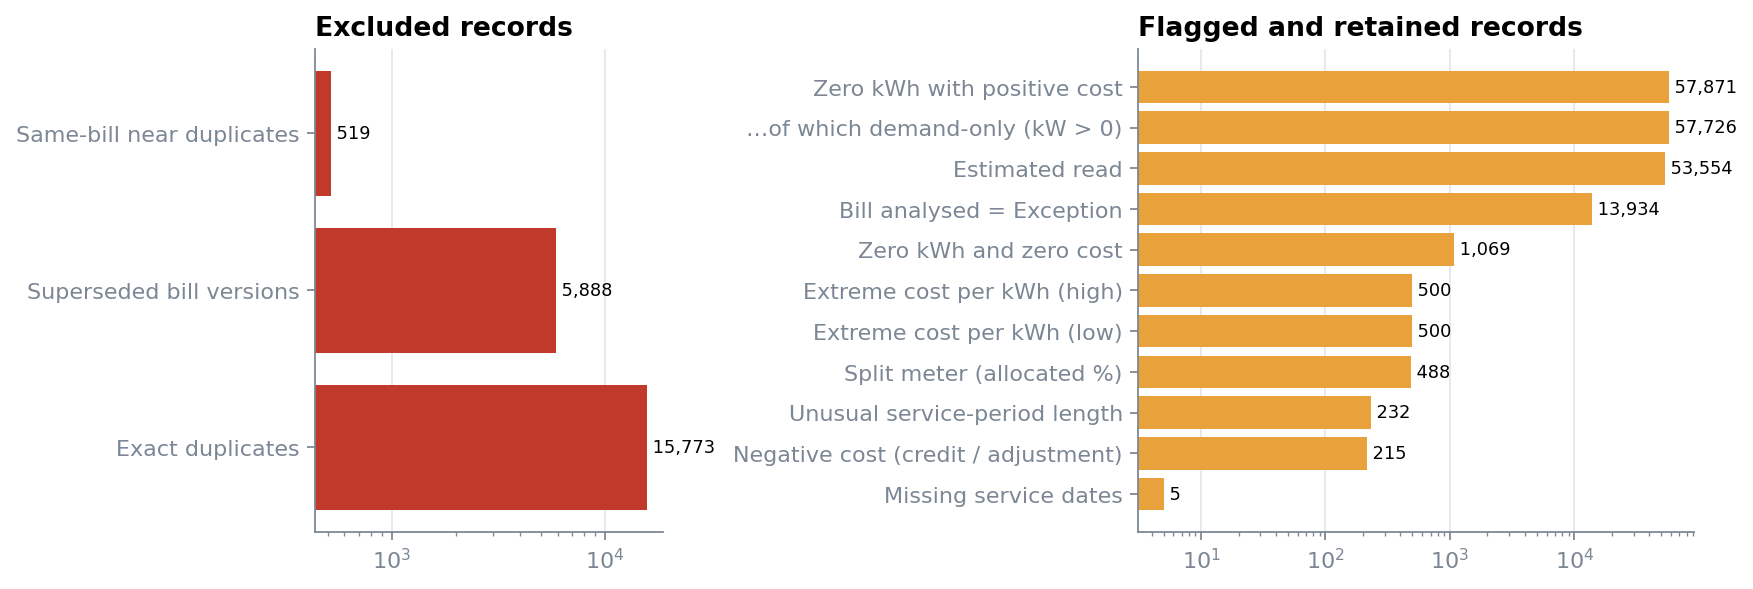

In [15]:
display(Image(str(config.FIGURES / "01_data_quality.png")))

## Outputs
- `data/processed/fact_development_month.csv`: clean monthly table with record counts and quality flags
- `data/processed/exclusion_log.csv`: every excluded `record_id` with its reason
- `data/processed/flagged_records.csv`: credits, extreme rates and unusual service periods
- `reports/data_quality_report.md`: generated report

These are written by `python -m nycha_energy.pipeline`.